# From a signal to a concentration

The band height and the whole-spectrum score follow the dissolved solute, but they have no unit. Calibration
ties them to kg of solute per kg of solvent, using moments of a run where the composition is known. This
notebook does that for the two datasets that have such moments:

1. **Caffeine in water**, from the band height.
2. **Azithromycin in ethyl acetate**, from the whole-spectrum score.

It starts where the signal step ended, at the reduced tables in the repository, so it needs no raw files.
The calibration functions are in `PharmaPy.PATCalibration`.

The package also has `PharmaPy.Calibration.PCR_calibration`, a regression on many standards of known
concentration. These runs hold two or three known states each, so a calibration with a few physical constants
is used here instead.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from PharmaPy import PATCalibration

# The two datasets are in examples/pat of the repository; find that folder from this notebook.
DATA = next(folder / "examples" / "pat" for folder in (Path.cwd(), *Path.cwd().parents)
            if (folder / "examples" / "pat" / "caffeine" / "runs.json").is_file())

ZERO_CELSIUS = 273.15  # [K]
# Solvent only, slurry and dissolved; then two neutrals.
AQUA, BLUE, ORANGE, INK, MUTED = "#1baf7a", "#2a78d6", "#eb6834", "#2b2a27", "#8a8882"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "figure.dpi": 110,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})


def between(values, window):
    """Return a mask of the values inside a window, both ends included."""
    return (values >= window[0]) & (values <= window[1])


def read_description(case):
    """Return the description of a dataset: its recipe, its runs and the windows of known state."""
    return json.loads((case / "runs.json").read_text(encoding="utf-8"))


def read_table(case, run_id, kind):
    """Return {column: values} of a reduced table: a row of titles, a row of units, then numbers."""
    table = case / "reduced" / ("%s_%s.csv" % (run_id, kind))
    titles = table.read_text(encoding="utf-8").splitlines()[0].split(",")
    return dict(zip(titles, np.genfromtxt(table, delimiter=",", skip_header=2, unpack=True)))

## Part 1. Caffeine in water: band height

Read the band height of the reference run and the liquid temperature at each spectrum. The charge comes from
the dataset description: the recipe of a fresh batch.

In [2]:
case = DATA / "caffeine"
description = read_description(case)
settings = description["band_calibration"]
run_id = settings["reference_run"]  # the first run of the campaign, the only one with solvent-only spectra
ir = read_table(case, run_id, "ir")
log = read_table(case, run_id, "temperature")
time, height = ir["time"], ir["band_height"]  # [s], [-]
temperature = np.interp(time, log["time"], log["external_temperature"], left=np.nan, right=np.nan)  # [K]; none before the log started

charge = description["charge"]
charge_ratio = charge["solute_mass_g"] / charge["solvent_mass_g"]  # [kg/kg]
print("run %s: %d spectra" % (run_id, time.size))
print("charge: %.4f g %s in %.0f g %s = %.5f kg/kg" % (charge["solute_mass_g"], charge["solute"], charge["solvent_mass_g"], charge["solvent"], charge_ratio))

run high_seed_slow_cool: 663 spectra
charge: 16.5434 g caffeine in 350 g water = 0.04727 kg/kg


### The model and what it needs

The band height is taken as a straight line in the dissolved solute, with a slope that changes a little with
temperature:

$$\text{height} = \text{baseline} + \big(\text{slope} + \text{slope per kelvin}\cdot(T - T_\text{ref})\big)\cdot\text{ratio}$$

`ratio` is the dissolved solute per solvent [kg/kg]. Three constants need three known states, and this run has them:

- **Solvent only**, before the caffeine went in: ratio 0. It gives the baseline.
- **Whole charge dissolved at 45 °C** and again **at 37 °C**: the ratio is the charge. The two holds give the
  slope and its change with temperature.

The slurry at 20 °C is what the calibration is for: its composition is not known.

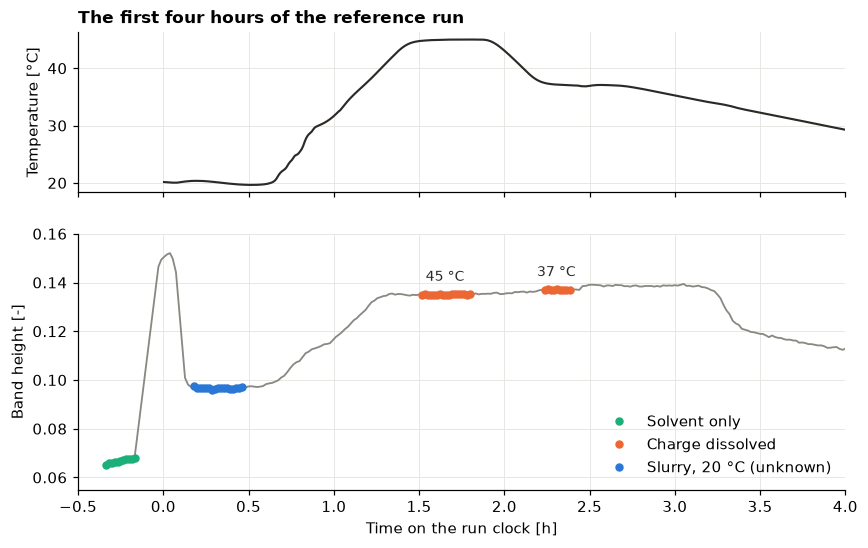

In [3]:
STATES = {  # name: (window on the run clock [s], colour)
    "Solvent only": (settings["solvent_window_s"], AQUA),
    "Charge dissolved, 45 °C": (settings["dissolved_windows_s"][0], ORANGE),
    "Charge dissolved, 37 °C": (settings["dissolved_windows_s"][1], ORANGE),
    "Slurry, 20 °C (unknown)": (settings["slurry_start_window_s"], BLUE),
}
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, height_ratios=(1, 1.6))
top.plot(log["time"] / 3600, log["external_temperature"] - ZERO_CELSIUS, color=INK, lw=1.4)
top.set(ylabel="Temperature [°C]", title="The first four hours of the reference run")
bottom.plot(time / 3600, height, color=MUTED, lw=1.2)
for name, (window, colour) in STATES.items():
    inside = between(time, window)
    bottom.plot(time[inside] / 3600, height[inside], "o", color=colour, ms=4.5, label=None if name.endswith("37 °C") else name.replace(", 45 °C", ""))
    if "dissolved" in name:
        bottom.annotate(name[-5:], xy=(np.mean(window) / 3600, height[inside].mean()), xytext=(0, 9), textcoords="offset points",
                        ha="center", color=INK, fontsize=9)
bottom.set(xlabel="Time on the run clock [h]", ylabel="Band height [-]", xlim=(-0.5, 4.0), ylim=(0.055, 0.16))
bottom.legend(frameon=False, loc="lower right");

### Solve the three constants

`window_statistics` gives the median height of a window and `fit_band_slope` solves the slope and its temperature
coefficient from the two dissolved holds.

In [4]:
REFERENCE_TEMPERATURE = settings["reference_temperature_K"]  # [K] the seeding hold, 37 C

baseline, _, _ = PATCalibration.window_statistics(time, height, *settings["solvent_window_s"])  # [-]
holds = []  # (height [-], temperature [K]) of the two dissolved holds
for window in settings["dissolved_windows_s"]:
    median, _, _ = PATCalibration.window_statistics(time, height, *window)
    holds.append((median, float(temperature[between(time, window)].mean())))
(height_45, temperature_45), (height_37, temperature_37) = holds
slope, slope_per_kelvin = PATCalibration.fit_band_slope(
    [height_45, height_37], [temperature_45, temperature_37], charge_ratio, baseline, REFERENCE_TEMPERATURE)

print("baseline (solvent only)             : %.4f" % baseline)
print("height per kg/kg at %.1f C          : (%.4f - %.4f) / %.5f = %.3f" % (temperature_45 - ZERO_CELSIUS, height_45, baseline, charge_ratio, (height_45 - baseline) / charge_ratio))
print("height per kg/kg at %.1f C          : (%.4f - %.4f) / %.5f = %.3f" % (temperature_37 - ZERO_CELSIUS, height_37, baseline, charge_ratio, (height_37 - baseline) / charge_ratio))
print("slope at 37 C %.3f per kg/kg, changing by %+.5f per kelvin (%.2f %% per kelvin)" % (slope, slope_per_kelvin, 100 * slope_per_kelvin / slope))

baseline (solvent only)             : 0.0666
height per kg/kg at 45.0 C          : (0.1351 - 0.0666) / 0.04727 = 1.449
height per kg/kg at 37.2 C          : (0.1371 - 0.0666) / 0.04727 = 1.490
slope at 37 C 1.491 per kg/kg, changing by -0.00538 per kelvin (-0.36 % per kelvin)


The calibration as a picture. Each line is the model at one temperature. Reading a concentration means going
from a measured height across to the line of its temperature and down to the axis, shown for the slurry.

slurry at 20.1 C: height 0.0967 reads 0.0190 kg/kg, 40 % of the charge


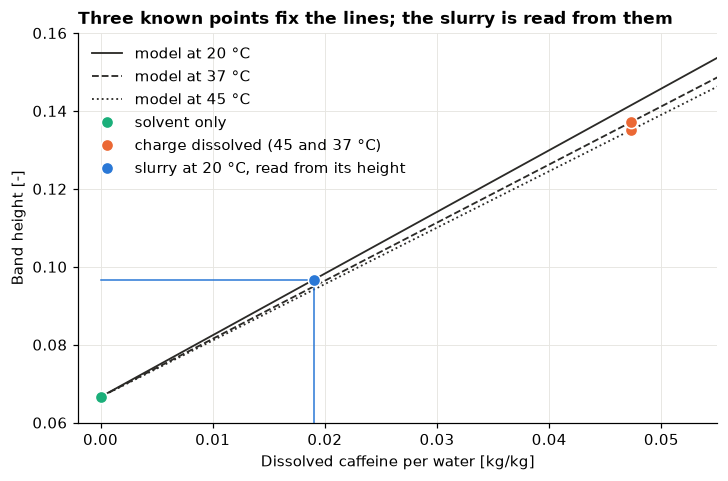

In [5]:
slurry_window = settings["slurry_start_window_s"]
slurry_height, _, _ = PATCalibration.window_statistics(time, height, *slurry_window)  # [-]
slurry_temperature = float(temperature[between(time, slurry_window)].mean())  # [K]
slurry_ratio = float(PATCalibration.ratio_from_band_height(
    slurry_height, slurry_temperature, baseline, slope, slope_per_kelvin, REFERENCE_TEMPERATURE))  # [kg/kg]

grid = np.array([0.0, 0.055])  # [kg/kg]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for celsius, style in ((20.0, "-"), (37.0, "--"), (45.0, ":")):
    line = PATCalibration.band_height_from_ratio(grid, celsius + ZERO_CELSIUS, baseline, slope, slope_per_kelvin, REFERENCE_TEMPERATURE)
    ax.plot(grid, line, color=INK, lw=1.2, ls=style, label="model at %.0f °C" % celsius)
ax.plot([0.0], [baseline], "o", color=AQUA, ms=8, mec="white", label="solvent only")
ax.plot([charge_ratio, charge_ratio], [height_45, height_37], "o", color=ORANGE, ms=8, mec="white", label="charge dissolved (45 and 37 °C)")
ax.plot([0.0, slurry_ratio, slurry_ratio], [slurry_height, slurry_height, 0.06], color=BLUE, lw=1.0)
ax.plot([slurry_ratio], [slurry_height], "o", color=BLUE, ms=8, mec="white", label="slurry at 20 °C, read from its height")
ax.set(xlabel="Dissolved caffeine per water [kg/kg]", ylabel="Band height [-]", xlim=(-0.002, 0.055), ylim=(0.06, 0.16),
       title="Three known points fix the lines; the slurry is read from them")
ax.legend(frameon=False, loc="upper left")
print("slurry at %.1f C: height %.4f reads %.4f kg/kg, %.0f %% of the charge" % (slurry_temperature - ZERO_CELSIUS, slurry_height, slurry_ratio, 100 * slurry_ratio / charge_ratio))

### Apply it to the whole run

`ratio_from_band_height` turns every band height with a logged temperature into a concentration.

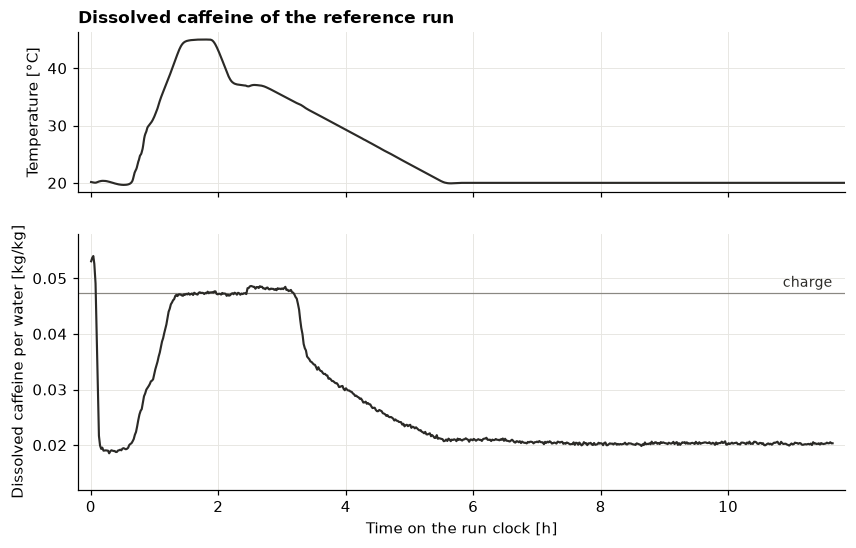

In [6]:
logged = np.isfinite(temperature)
ratio = PATCalibration.ratio_from_band_height(height[logged], temperature[logged], baseline, slope, slope_per_kelvin, REFERENCE_TEMPERATURE)  # [kg/kg]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, height_ratios=(1, 1.6))
top.plot(log["time"] / 3600, log["external_temperature"] - ZERO_CELSIUS, color=INK, lw=1.4)
top.set(ylabel="Temperature [°C]", title="Dissolved caffeine of the reference run")
bottom.axhline(charge_ratio, color=MUTED, lw=0.8)
bottom.text(time[-1] / 3600, charge_ratio + 0.0006, "charge", color=INK, fontsize=9, ha="right", va="bottom")
bottom.plot(time[logged] / 3600, ratio, color=INK, lw=1.4)
bottom.set(xlabel="Time on the run clock [h]", ylabel="Dissolved caffeine per water [kg/kg]", xlim=(-0.2, time[-1] / 3600 + 0.2), ylim=(0.012, 0.058));

### How far to trust it

The two dissolved holds read the charge by construction, so they are no test. What can be tested:

In [7]:
solvent_heights = height[between(time, settings["solvent_window_s"])]
last_half_hour = between(time[logged], (time[-1] - settings["slurry_end_duration_s"], time[-1]))
end_ratio = float(np.median(ratio[last_half_hour]))  # [kg/kg]


def slurry_with(other_baseline):
    """Return the slurry reading [kg/kg] when the calibration is solved with another baseline."""
    other = PATCalibration.fit_band_slope([height_45, height_37], [temperature_45, temperature_37], charge_ratio, other_baseline, REFERENCE_TEMPERATURE)
    return float(PATCalibration.ratio_from_band_height(slurry_height, slurry_temperature, other_baseline, *other, REFERENCE_TEMPERATURE))


recipe_at_20 = (charge["solute_mass_g"] - charge["theoretical_yield_g"]) / charge["solvent_mass_g"]  # [kg/kg] the recipe sheet's estimate
print("slurry at 20 C, start of the run : %.4f kg/kg" % slurry_ratio)
print("slurry at 20 C, end of the run   : %.4f kg/kg (%+.0f %%)" % (end_ratio, 100 * (end_ratio / slurry_ratio - 1)))
print("solvent-only height ranges from %.4f to %.4f over its %d spectra; the slurry then reads %.4f to %.4f kg/kg"
      % (solvent_heights.min(), solvent_heights.max(), solvent_heights.size, slurry_with(solvent_heights.max()), slurry_with(solvent_heights.min())))
print("the recipe sheet expected %.4f kg/kg to stay dissolved at 20 C" % recipe_at_20)

slurry at 20 C, start of the run : 0.0190 kg/kg
slurry at 20 C, end of the run   : 0.0203 kg/kg (+7 %)
solvent-only height ranges from 0.0651 to 0.0681 over its 11 spectra; the slurry then reads 0.0184 to 0.0196 kg/kg
the recipe sheet expected 0.0146 kg/kg to stay dissolved at 20 C


### The other runs

The lab reuses the batch from one run to the next and adjusts it in between. So a later run may hold a different
charge, and it has no solvent-only spectra of its own. There are three ways to read such a run:

- carry the constants of the reference run over unchanged;
- keep the baseline and solve a slope of its own with `fit_band_slope`;
- keep the slope and solve a baseline of its own with `fit_band_baseline`.

The last two take the run to hold the recipe charge. A test separates the three: a slurry at rest at 20 °C is
saturated, so it must read the same in every run.

In [8]:
def known_states(other_id):
    """Return (height [-], temperature [K]) of the two dissolved holds and of the starting slurry of a run."""
    spectra, thermostat = read_table(case, other_id, "ir"), read_table(case, other_id, "temperature")
    with_temperature = between(spectra["time"], (thermostat["time"][0], thermostat["time"][-1]))
    run_time, run_height = spectra["time"][with_temperature], spectra["band_height"][with_temperature]
    run_temperature = np.interp(run_time, thermostat["time"], thermostat["external_temperature"])  # [K]
    states = []
    for window in (*settings["dissolved_windows_s"], settings["slurry_start_window_s"]):
        median, _, _ = PATCalibration.window_statistics(run_time, run_height, *window)
        states.append((median, float(run_temperature[between(run_time, window)].mean())))
    return states


print("%-22s %22s %26s %26s" % ("slurry at 20 C [kg/kg]", "constants carried over", "own slope, same baseline", "same slope, own baseline"))
readings = {"carried": [], "own slope": [], "own baseline": []}
for other_id in settings["runs"]:
    first_hold, second_hold, (start_height, start_temperature) = known_states(other_id)
    heights, temperatures = [first_hold[0], second_hold[0]], [first_hold[1], second_hold[1]]
    own_slope = PATCalibration.fit_band_slope(heights, temperatures, charge_ratio, baseline, REFERENCE_TEMPERATURE)
    own_baseline = PATCalibration.fit_band_baseline(heights, temperatures, charge_ratio, slope, slope_per_kelvin, REFERENCE_TEMPERATURE)
    constants = {"carried": (baseline, slope, slope_per_kelvin), "own slope": (baseline, *own_slope), "own baseline": (own_baseline, slope, slope_per_kelvin)}
    for name, (run_baseline, run_slope, run_slope_per_kelvin) in constants.items():
        readings[name].append(float(PATCalibration.ratio_from_band_height(
            start_height, start_temperature, run_baseline, run_slope, run_slope_per_kelvin, REFERENCE_TEMPERATURE)))
    print("%-22s %22.4f %26.4f %26.4f" % (other_id, *(values[-1] for values in readings.values())))
print("%-22s %21.0f%% %25.0f%% %25.0f%%" % ("spread of the three", *(100 * np.ptp(values) / np.mean(values) for values in readings.values())))

# The dataset folder holds the last two solutions, written by the workflow script examples/pat/calibrate_band.py.
stored = json.loads((case / "band_calibration.json").read_text(encoding="utf-8"))["runs"]
for row, other_id in enumerate(settings["runs"]):
    assert abs(readings["own slope"][row] - stored[other_id]["common_baseline"]["slurry_start_ratio"]) < 1e-6
    assert abs(readings["own baseline"][row] - stored[other_id]["common_slope"]["slurry_start_ratio"]) < 1e-6

slurry at 20 C [kg/kg] constants carried over   own slope, same baseline   same slope, own baseline
high_seed_slow_cool                    0.0190                     0.0190                     0.0190
low_seed_slow_cool                     0.0146                     0.0156                     0.0174
low_seed_fast_cool                     0.0154                     0.0163                     0.0181
spread of the three                       27%                        20%                         9%


What this shows:

- **Inside the reference run the calibration is firm to about 3 %.** That is the range of the solvent-only
  height, 0.0184 to 0.0196 kg/kg for the slurry. An error in the recipe charge comes on top and scales every
  reading by the same factor.
- **The slurry reads 7 % higher at the end of the run than at its start.** The calibration cannot say whether
  the solution really holds more caffeine then.
- **The recipe sheet expected 0.0146 kg/kg at 20 °C; the IR reads 0.0190.** The sheet's figure is an estimate,
  not a measurement of this batch.
- **Between runs the calibration does not carry over unchanged.** With the constants of the reference run the
  slurries at 20 °C of the three runs spread by 27 %. A baseline of its own for each run brings that to 9 %. That
  treatment still takes every run to hold the recipe charge, which the reuse of the batch puts in doubt.

Solvent-only spectra at the start of every run and weighed masses would remove most of this.

## Part 2. Azithromycin in ethyl acetate: whole-spectrum score

The score is already at one temperature (37 °C) and is counted from each run's own dissolved charge. One unit
is the same amount of solute in every run. So the model is one line per run with a common slope:

$$\text{ratio} = \text{charge of the run} + \kappa\cdot\text{score}$$

Two things are unknown: the sensitivity $\kappa$ [kg/kg per score unit], one for the dataset, and the charge of
each run, because the batch is reused.

In [9]:
case = DATA / "azithromycin"
description = read_description(case)
summary = json.loads((case / "reduced" / "ir_score.json").read_text(encoding="utf-8"))
charge = description["charge"]
recipe_ratio = charge["solute_mass_g"] / charge["solvent_mass_g"]  # [kg/kg] charge of a fresh batch
yield_ratio = charge["theoretical_yield_g"] / charge["solvent_mass_g"]  # [kg/kg] what the recipe expects to crystallize at 20 C
saturated_at_20 = recipe_ratio - yield_ratio  # [kg/kg] what the recipe expects to stay dissolved at 20 C

runs = {}  # run id: (time [s], score [-], temperature [K]), in the order the runs were made
for run in description["runs"]:
    ir = read_table(case, run["id"], "ir")
    log = read_table(case, run["id"], "temperature")
    runs[run["id"]] = (ir["time"], ir["score"], np.interp(ir["time"], log["time"], log["external_temperature"]))
first_run, second_run, third_run, fourth_run = runs

print("recipe: %.0f g %s in %.0f g %s = %.4f kg/kg" % (charge["solute_mass_g"], charge["solute"], charge["solvent_mass_g"], charge["solvent"], recipe_ratio))
print("theoretical yield %.0f g, so %.4f kg/kg stay dissolved at 20 C" % (charge["theoretical_yield_g"], saturated_at_20))

recipe: 140 g azithromycin_dihydrate in 300 g ethyl_acetate = 0.4667 kg/kg
theoretical yield 74 g, so 0.2200 kg/kg stay dissolved at 20 C


### What is known

- **Level.** The first run of the campaign is the fresh batch, so its charge is the recipe.
- **Scale.** The recipe's theoretical yield says how much stays dissolved at 20 °C. A slurry at rest at 20 °C
  is saturated, so it holds that much.

Every run starts with a hold at 20 °C. Which of them is a slurry at rest?

high_seed_fast_cool    score -1.006, scatter 0.054
low_seed_fast_cool     score +0.009, scatter 0.005
high_seed_slow_cool    score -1.111, scatter 0.001
low_seed_slow_cool     score -1.000, scatter 0.002


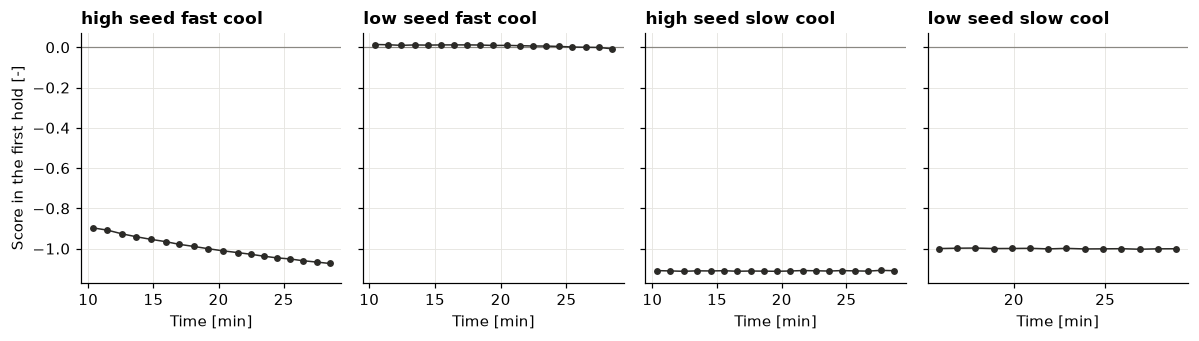

In [10]:
FIRST_HOLD = (600.0, 1750.0)  # [s] hold at 20 C at the start of every run
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2), sharey=True)
start = {}  # run id: (median score [-], scatter [-]) in the first hold
for ax, (name, (run_time, score, _)) in zip(axes, runs.items()):
    hold = between(run_time, FIRST_HOLD)
    start[name] = (float(np.median(score[hold])), float(score[hold].std()))
    ax.axhline(0.0, color=MUTED, lw=0.8)
    ax.plot(run_time[hold] / 60, score[hold], "o-", color=INK, ms=3.5, lw=1.0)
    ax.set(xlabel="Time [min]", title=name.replace("_", " "))
    ax.title.set_fontsize(9)
axes[0].set_ylabel("Score in the first hold [-]")
fig.tight_layout()
for name, (median, scatter) in start.items():
    print("%-22s score %+.3f, scatter %.3f" % (name, median, scatter))

- The **first run** is not at rest: its score is still falling through the hold.
- The **second run** starts as a clear solution, with a score near zero.
- The **third and fourth runs** start as slurries at rest, with a scatter of 0.001 to 0.002. They can carry the scale.

The scale then needs the third run's charge tied to the first run's. The reduction already compared the
dissolved spectrum of every run with that of the first run and wrote the difference to `ir_score.json`, in
score units:

In [11]:
against = summary["dissolved_spectrum_against_comparison_run"]  # dissolved spectrum of each run against the first run's
for name, terms in against.items():
    print("%-22s dissolved charge %+.3f score units from the first run; unexplained remainder %.4f absorbance" % (name, terms["score"], terms["residual"]))

high_seed_fast_cool    dissolved charge +0.000 score units from the first run; unexplained remainder 0.0000 absorbance
low_seed_fast_cool     dissolved charge +0.082 score units from the first run; unexplained remainder 0.0009 absorbance
high_seed_slow_cool    dissolved charge -0.176 score units from the first run; unexplained remainder 0.0015 absorbance
low_seed_slow_cool     dissolved charge -0.742 score units from the first run; unexplained remainder 0.2187 absorbance


### Solve the sensitivity and the charges

The third run supplies the scale. Between the dissolved charge of the first run (the recipe) and the slurry of
the third run (saturated at 20 °C) lie the theoretical yield in kg/kg and a known number of score units.
`fit_score_sensitivity` takes those two states, `ratio_from_score` converts a score with the charge of its run,
and `charge_from_score` gives a charge from one known state.

The comparison of the fourth run leaves a remainder of 0.22 absorbance, against 0.001 for the others: its
spectra sit on a different baseline. Its number is not used.

In [12]:
# One zero for both states: the dissolved charge of the first run. On it, the slurry of the third run is its own
# score plus the score of the third run's dissolved charge against the first run.
third_slurry = against[third_run]["score"] + start[third_run][0]  # [-]
kappa = PATCalibration.fit_score_sensitivity(ratios=[recipe_ratio, saturated_at_20], scores=[0.0, third_slurry])  # [kg/kg per score unit]

# Charges [kg/kg]: the first run's, moved by the score of each run's dissolved charge against the first run.
charges = {name: float(PATCalibration.ratio_from_score(against[name]["score"], recipe_ratio, kappa)) for name in (first_run, second_run, third_run)}
# The fourth run cannot be compared with the first. Its own slurry at rest gives its charge instead.
charges[fourth_run] = PATCalibration.charge_from_score(saturated_at_20, start[fourth_run][0], kappa)

print("sensitivity: %.4f kg/kg over %.3f score units = %.4f kg/kg per score unit" % (yield_ratio, -third_slurry, kappa))
for name, value in charges.items():
    print("%-22s charge %.4f kg/kg = %.1f g in %.0f g of solvent" % (name, value, value * charge["solvent_mass_g"], charge["solvent_mass_g"]))

sensitivity: 0.2467 kg/kg over 1.287 score units = 0.1917 kg/kg per score unit
high_seed_fast_cool    charge 0.4667 kg/kg = 140.0 g in 300 g of solvent
low_seed_fast_cool     charge 0.4824 kg/kg = 144.7 g in 300 g of solvent
high_seed_slow_cool    charge 0.4329 kg/kg = 129.9 g in 300 g of solvent
low_seed_slow_cool     charge 0.4117 kg/kg = 123.5 g in 300 g of solvent


### Apply it to the four runs

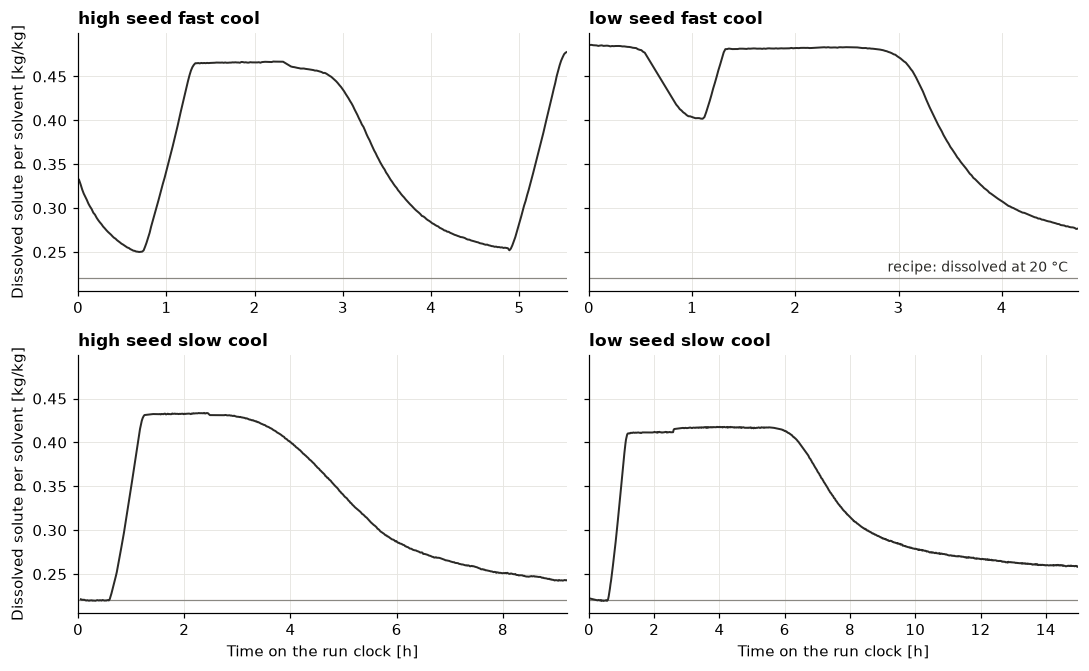

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2), sharey=True)
ratios = {}  # run id: dissolved solute per solvent [kg/kg]
for ax, (name, (run_time, score, _)) in zip(axes.ravel(), runs.items()):
    ratios[name] = PATCalibration.ratio_from_score(score, charges[name], kappa)
    ax.axhline(saturated_at_20, color=MUTED, lw=0.8)
    ax.plot(run_time / 3600, ratios[name], color=INK, lw=1.3)
    ax.set(title=name.replace("_", " "), xlim=(0, run_time[-1] / 3600))
axes[0, 1].text(0.98, saturated_at_20 + 0.004, "recipe: dissolved at 20 °C", color=INK, fontsize=9, ha="right", va="bottom",
                transform=axes[0, 1].get_yaxis_transform())
for ax in axes[1]:
    ax.set_xlabel("Time on the run clock [h]")
for ax in axes[:, 0]:
    ax.set_ylabel("Dissolved solute per solvent [kg/kg]")
fig.tight_layout()

### How far to trust it

The first run's charge, the third run's slurry and the fourth run's slurry read their assumed values by
construction. What can be tested:

In [14]:
seed_ratio = description["runs"][0]["seed_mass_g"] / charge["solvent_mass_g"]  # [kg/kg] seed added in the first run
print("second run minus first run: %+.4f kg/kg; the seed added in the first run was %.4f kg/kg (%.1f g against %.1f g)"
      % (charges[second_run] - charges[first_run], seed_ratio, (charges[second_run] - charges[first_run]) * charge["solvent_mass_g"],
         description["runs"][0]["seed_mass_g"]))
seeding = {run["id"]: run["seeding_time_s"] for run in description["runs"]}  # [s]
for name, (run_time, score, run_temperature) in runs.items():
    cold = np.flatnonzero((run_time > seeding[name]) & (np.abs(run_temperature - (20.0 + ZERO_CELSIUS)) < 0.1))  # back at 20 C
    last = cold[run_time[cold] >= run_time[cold[-1]] - 1800.0]
    trend = np.polyfit(run_time[last] / 3600, ratios[name][last], 1)[0]  # [kg/kg per h]
    print("%-22s last half hour at 20 C: %.3f kg/kg, changing by %+.3f kg/kg per hour" % (name, np.median(ratios[name][last]), trend))
run_time, score, _ = runs[fourth_run]
step = np.median(score[between(run_time, (seeding[fourth_run] + 300.0, seeding[fourth_run] + 1200.0))]) - np.median(
    score[between(run_time, (seeding[fourth_run] - 1200.0, seeding[fourth_run] - 300.0))])  # [-]
fourth_seed = description["runs"][3]["seed_mass_g"] / charge["solvent_mass_g"]  # [kg/kg]
print("fourth run, where the seed dissolved: the reading steps by %+.4f kg/kg at the seed addition; the seed was %.4f kg/kg"
      % (kappa * step, fourth_seed))
low_seed = description["runs"][1]
other_yield = low_seed["seed_mass_g"] / (low_seed["seed_percent_of_yield"] / 100.0)  # [g] the yield the low seed implies
print("the low seed, %.1f g as %.0f %% of the yield, implies a yield of %.0f g instead of %.0f g: the sensitivity would be %.4f"
      % (low_seed["seed_mass_g"], low_seed["seed_percent_of_yield"], other_yield, charge["theoretical_yield_g"],
         PATCalibration.fit_score_sensitivity([recipe_ratio, recipe_ratio - other_yield / charge["solvent_mass_g"]], [0.0, third_slurry])))

second run minus first run: +0.0158 kg/kg; the seed added in the first run was 0.0123 kg/kg (4.7 g against 3.7 g)
high_seed_fast_cool    last half hour at 20 C: 0.263 kg/kg, changing by -0.031 kg/kg per hour
low_seed_fast_cool     last half hour at 20 C: 0.283 kg/kg, changing by -0.032 kg/kg per hour
high_seed_slow_cool    last half hour at 20 C: 0.243 kg/kg, changing by -0.007 kg/kg per hour
low_seed_slow_cool     last half hour at 20 C: 0.259 kg/kg, changing by -0.001 kg/kg per hour
fourth run, where the seed dissolved: the reading steps by +0.0049 kg/kg at the seed addition; the seed was 0.0027 kg/kg
the low seed, 0.8 g as 1 % of the yield, implies a yield of 80 g instead of 74 g: the sensitivity would be 0.2072


What this shows:

- **Two independent tests agree to about 1 g of solute.** The second run starts as a clear solution, so it is
  taken as the first run redissolved with its seed; the upturn at the end of the first panel is that
  reheating. The calibration puts its charge 4.7 g above the first run's, and the seed was 3.7 g. In the fourth
  run the seed dissolved: the reading steps by 0.0049 kg/kg (1.5 g) for a seed of 0.8 g.
- **One gap stays open.** The fourth run starts as a slurry at rest, taken as 0.220 kg/kg, and ends nearly at
  rest at 0.259. Two slurries at rest at 20 °C should read the same. Either the solid or the solution differs
  at the end, or the score reads that state differently. These data cannot tell which.
- **The other runs end while still crystallizing**, at 0.243 to 0.283 kg/kg, so their ends are no test.
- **The scale rests on the theoretical yield of 74 g.** The low seed implies 80 g, which would raise $\kappa$ by 8 %.
- **The levels rest on the recipe.** The first run is taken as a fresh batch of exactly 140 g in 300 g; the
  masses were not weighed, and any solvent lost between runs is not seen.

## What each route needs

| | Band height | Whole-spectrum score |
|---|---|---|
| Zero | Solvent-only spectra | None: the score counts from the run's own dissolved charge |
| Scale | The charge dissolved | Two compositions: a charge, and a slurry at rest of known solubility |
| Temperature | In the calibration, from two dissolved holds | Already removed when the score was made |
| From run to run | The baseline can shift and the charge can differ | The charge of each run, from its dissolved spectrum |

Both calibrations are functions of `PharmaPy.PATCalibration`. Which states are known, and which run carries
them, is the user's reading of the runs, as in the two parts above.